<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-01/lab-003a-trained-networks-pytorch.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning in Classical and Quantum Physics
2026/2027 <br>
**Author:** Marcin Płodzień <br>
**Lab:** 003a <br>
<hr/>

# Lab 003a — Trained networks in PyTorch

Training a network is rarely the last step. A trained network is a set of arrays (the parameters) together with a description of the computation (the architecture), and most of the daily work consists of doing things *with* it: storing it, reloading it, looking at what it has learned, cutting it into pieces, adding layers, and re-using it for a new problem. This lab is the toolbox for these operations.

We train one small **convolutional neural network (CNN)** on the handwritten digits 0–4 of MNIST and then use it in every section. Section 1 trains the CNN once, writes its parameters to disk, loads them into a fresh model, and checks that the predictions are identical. Section 2 inspects the trained model: its layers, parameter shapes and counts, access to single weights, and the distinction between trainable and frozen parameters. Section 3 looks inside the network, at the first-layer kernels drawn as images and at the feature maps of one digit after each convolutional layer, recorded with forward hooks. Section 4 performs model surgery: it cuts the network into a feature extractor, attaches a new head, inserts a layer and replaces a layer. Section 5 uses these tools for transfer learning on a new task, the digits 5–9 with few labelled images, comparing a random initialisation, a frozen trained body with a new head, and fine-tuning of all parameters. Section 6 lists every operation of the lab in PyTorch and in JAX/Flax side by side.

The twin notebook **Lab 003b** does exactly the same in JAX with Flax NNX and optax: same data, same architecture, same sections, same printed quantities. The two can be read side by side.

The network is a convolutional neural network (CNN): its first layers slide small learned filters over the image, so the same pattern detector is applied everywhere. Its activation function is the rectified linear unit, $\mathrm{ReLU}(z)=\max(0,z)$, which passes positive inputs and blocks negative ones. It is trained with Adam (adaptive moment estimation), a gradient-descent optimiser that adapts the step size of every parameter to the recent size of its gradients. Everything runs on the central processing unit (CPU); the same code runs unchanged on a graphics processing unit (GPU).

> To run this notebook in Google Colab, follow these steps:
> 1. Go to <https://colab.research.google.com> → *File → Upload notebook*. The notebook runs on the **CPU** (the first code cell hides all GPUs); the model and the data sets are small enough to finish in a few minutes.
> 2. `numpy`, `matplotlib` and `torch` are pre-installed in Colab.
> 3. The notebook uses the four MNIST files (`*-ubyte.gz`); if they are missing, it downloads them.
> 4. Run the cells *in order*: later cells use variables defined earlier. If the state becomes inconsistent: *Runtime → Restart session* and run from the top.

In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = ""     # hide all GPUs: everything runs on the CPU (set before importing torch)
os.environ["JAX_PLATFORMS"] = "cpu"         # the same choice for JAX, in case it is imported in this session

import copy, gzip, time, urllib.request
from collections import OrderedDict
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

UJBlue, UJNavy, DSOrange, UJGray = "#005CA7", "#002B5C", "#D35A05", "#5A6270"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 11, "axes.labelsize": 10, "legend.frameon": False})
def noframe(ax):                            # image panels: no ticks, no frame
    ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values(): sp.set_visible(False)

torch.set_num_threads(min(4, os.cpu_count()))   # small convolutions: more threads add more synchronisation than speed
t_start = time.time()
print("PyTorch", torch.__version__, "| CPU threads used:", torch.get_num_threads(), "| GPU visible:", torch.cuda.is_available())

PyTorch 2.9.0+cpu | CPU threads used: 4 | GPU visible: False


<hr/>
## 1. Training and saving

### 1.1 The data: two tasks from one data set

MNIST contains $28\times28$ grayscale images of handwritten digits, $60\,000$ for training and $10\,000$ for testing. We split it into two tasks. The **source task** consists of the digits 0–4, with all training images of these digits; the CNN is trained on it in this section. The **target task** consists of the digits 5–9 and is used in Section 5. Its labels are shifted, $5\to0,\dots,9\to4$, so both tasks have 5 classes.

The files are in the raw IDX format: a short big-endian header (a magic number, then the sizes), followed by one byte per pixel; we read them with `gzip` and `numpy`. Pixels are scaled to $[0,1]$.

PyTorch convolutions expect image tensors in the layout `(N, C, H, W)`: batch size, channels, height, width. Our images are therefore stored as `(N, 1, 28, 28)`. (JAX/Flax uses `(N, H, W, C)`, see Lab 003b.)

In [2]:
MNIST_DIR = "data/MNIST_raw"
MNIST_FILES = ["train-images-idx3-ubyte.gz", "train-labels-idx1-ubyte.gz",
               "t10k-images-idx3-ubyte.gz", "t10k-labels-idx1-ubyte.gz"]
if not all(os.path.exists(f"{MNIST_DIR}/{f}") for f in MNIST_FILES):
    os.makedirs(MNIST_DIR, exist_ok=True)
    for f in MNIST_FILES:
        urllib.request.urlretrieve(f"https://storage.googleapis.com/cvdf-datasets/mnist/{f}", f"{MNIST_DIR}/{f}")

def read_idx(path):
    with gzip.open(path, "rb") as fh:
        data = fh.read()
    ndim = data[3]                                                  # 3 for images, 1 for labels
    shape = np.frombuffer(data[4:4 + 4 * ndim], dtype=">i4")        # big-endian int32 sizes
    return np.frombuffer(data[4 + 4 * ndim:], dtype=np.uint8).reshape(shape)

Xtr_all = read_idx(f"{MNIST_DIR}/{MNIST_FILES[0]}").astype(np.float32) / 255.0   # (60000, 28, 28)
ytr_all = read_idx(f"{MNIST_DIR}/{MNIST_FILES[1]}").astype(np.int64)
Xte_all = read_idx(f"{MNIST_DIR}/{MNIST_FILES[2]}").astype(np.float32) / 255.0   # (10000, 28, 28)
yte_all = read_idx(f"{MNIST_DIR}/{MNIST_FILES[3]}").astype(np.int64)

def task(X, y, digits):
    # images of the given digits as (N, 1, 28, 28) float32 and labels shifted to 0 .. len(digits)-1
    keep = np.isin(y, digits)
    return torch.tensor(X[keep][:, None, :, :]), torch.tensor(y[keep] - digits[0])

Xs_tr, ys_tr = task(Xtr_all, ytr_all, [0, 1, 2, 3, 4])     # source task: digits 0-4
Xs_te, ys_te = task(Xte_all, yte_all, [0, 1, 2, 3, 4])
Xt_pool, yt_pool = task(Xtr_all, ytr_all, [5, 6, 7, 8, 9]) # target task: labelled images are drawn from this pool in Section 5
Xt_te, yt_te = task(Xte_all, yte_all, [5, 6, 7, 8, 9])

assert Xs_tr.shape[1:] == (1, 28, 28) and Xs_tr.dtype == torch.float32
print("source task (digits 0-4): train", tuple(Xs_tr.shape), "| test", tuple(Xs_te.shape))
print("target task (digits 5-9): pool ", tuple(Xt_pool.shape), "| test", tuple(Xt_te.shape))
print("pixel range:", Xs_tr.min().item(), "to", Xs_tr.max().item())

source task (digits 0-4): train (30596, 1, 28, 28) | test (5139, 1, 28, 28)
target task (digits 5-9): pool  (29404, 1, 28, 28) | test (4861, 1, 28, 28)
pixel range: 0.0 to 1.0


### 1.2 The architecture: a convolutional body and a dense head

The network (conv–pool–conv–pool–dense–output) is split into two named parts, because Sections 4 and 5 treat them separately. The **body** (the convolutional feature extractor) maps an image to a feature vector of $32\cdot7\cdot7=1568$ numbers,
$$
(N,1,28,28)\xrightarrow{\text{conv }5\times5,\ 16}(N,16,28,28)\xrightarrow{\text{ReLU, max-pool }2}(N,16,14,14)\xrightarrow{\text{conv }3\times3,\ 32}(N,32,14,14)\xrightarrow{\text{ReLU, max-pool }2}(N,32,7,7)\xrightarrow{\text{flatten}}(N,1568).
$$
The **head** (the classifier) is a dense layer with ReLU followed by an output layer, $(N,1568)\xrightarrow{\text{fc, ReLU}}(N,64)\xrightarrow{\text{out}}(N,5)$, giving 5 logits (unnormalised log-probabilities of the classes).

`padding=2` for the $5\times5$ kernel and `padding=1` for the $3\times3$ kernel keep the height and width unchanged, so only the pooling layers halve them. Both parts are `nn.Sequential` containers built from an `OrderedDict`: every layer gets a readable name (`conv1`, `relu1`, …), which appears in the parameter names (`body.conv1.weight`) and lets us address single layers later.

In [3]:
class SmallCNN(nn.Module):
    def __init__(self, n_classes=5):
        super().__init__()
        self.body = nn.Sequential(OrderedDict([
            ("conv1",   nn.Conv2d(1, 16, kernel_size=5, padding=2)),    # (N,1,28,28)  -> (N,16,28,28)
            ("relu1",   nn.ReLU()),
            ("pool1",   nn.MaxPool2d(2)),                               # -> (N,16,14,14)
            ("conv2",   nn.Conv2d(16, 32, kernel_size=3, padding=1)),   # -> (N,32,14,14)
            ("relu2",   nn.ReLU()),
            ("pool2",   nn.MaxPool2d(2)),                               # -> (N,32,7,7)
            ("flatten", nn.Flatten()),                                  # -> (N,1568), order (channel, row, column)
        ]))
        self.head = nn.Sequential(OrderedDict([
            ("fc",      nn.Linear(32 * 7 * 7, 64)),                     # (N,1568) -> (N,64)
            ("relu3",   nn.ReLU()),
            ("out",     nn.Linear(64, n_classes)),                      # (N,64) -> (N,n_classes) logits
        ]))

    def forward(self, x):
        return self.head(self.body(x))

torch.manual_seed(0)
model = SmallCNN()
out = model(Xs_tr[:8])
assert out.shape == (8, 5) and model.body(Xs_tr[:8]).shape == (8, 1568)
print("logits of 8 images:", tuple(out.shape), "| feature vectors:", tuple(model.body(Xs_tr[:8]).shape))

logits of 8 images: (8, 5) | feature vectors: (8, 1568)


#### Drawing the network

A picture of the architecture helps to keep track of the shapes, and in Sections 4 and 5 it will also show which parts of the network are changed. A dense network can be drawn node by node, each node a circle and each weight a line (Lab 007), but for a convolutional layer such a drawing is not readable: `conv1` alone produces $16\cdot28\cdot28=12\,544$ numbers, each computed from a $5\times5$ patch of the image with the same 25 weights of its kernel. Convolutional networks are therefore drawn as block diagrams in which every intermediate result is a stack of feature maps. The function `draw_cnn` draws $C$ maps of $H\times W$ pixels as overlapping squares whose side is proportional to $H$ and whose number grows with $\log_2 C$, and writes the shape $H\times W\times C$ under the stack and the name of the layer that produced it above the arrow. Once the maps are flattened into a vector, the dense head is drawn with nodes and edges: every node a circle, every weight a line, and a wide layer with a limited number of circles, three dots for the omitted nodes and its true width under the column. A dashed line can mark the place where the network is cut into two parts, and an optional list `status` colours every layer as frozen, trained or new, which we use from Section 5 on.

The first cell contains the helpers for the columns of nodes: `nodes_shown` decides how many circles a layer of a given width gets (all of them up to `max_nodes`, then a number growing with the logarithm of the width), `draw_layer` draws one column, `connect` draws the lines of a dense layer between two columns, and `finish` sets equal scales on both axes and a figure size proportional to the drawing.

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle
from matplotlib.collections import LineCollection

SCALE = 0.42          # inches of figure per drawing unit; neighbouring nodes of a layer are 1 unit apart
NODE_COLORS = {"input": "#8A929E", "hidden": "#005CA7", "latent": "#D35A05", "output": "#002B5C",
               "cond": "#2E8B57", "noise": "#F2B28A"}


def text_height(fontsize, lines=1):
    """Height of `lines` lines of text of the given font size, in drawing units (used to place labels)."""
    return lines * 1.25 * fontsize / 72 / SCALE


def nodes_shown(n, max_nodes=8, growth=1.5):
    """Number of circles drawn for a layer of width n.
    Up to max_nodes every node is drawn. A wider layer gets max_nodes circles plus `growth` circles for every
    doubling of its width, so the column height still grows with the width: with the defaults a layer of
    16 nodes is drawn with 10 circles, 64 with 12, 256 with 16 and 784 with 18."""
    if n <= max_nodes:
        return n
    return max_nodes + int(round(growth * np.log2(n / max_nodes)))


def draw_layer(ax, x, n, y0=0.0, color=NODE_COLORS["hidden"], max_nodes=8, growth=1.5, r=0.32,
               top=None, bottom=None, show_width=True, fontsize=12):
    """Draw one layer of width n as a vertical column of circles at horizontal position x, centred at height y0.
    Returns the heights of the drawn circles, from top to bottom (needed to draw the edges).

    The circles are 1 unit apart. If the layer is wider than the number of circles (see nodes_shown), one slot
    in the middle of the column stays empty and gets three dots, which stand for the omitted nodes; the true
    width n is then the number written under the column. `top` and `bottom` are optional texts above and below."""
    k = nodes_shown(n, max_nodes, growth)
    capped = k < n
    slots = k + 1 if capped else k                         # one extra slot for the dots
    y = y0 + (slots - 1) / 2 - np.arange(slots)            # heights of the slots, from top to bottom
    if capped:
        mid = slots // 2
        ax.scatter([x] * 3, y[mid] + np.array([-0.25, 0.0, 0.25]), s=6, color="k", zorder=3)
        y = np.delete(y, mid)                              # no circle in the dotted slot
    for yi in y:
        ax.add_patch(Circle((x, yi), r, facecolor=color, edgecolor="k", lw=0.8, zorder=3))
    under = (f"{n}" if show_width else "") + (f"\n{bottom}" if bottom else "")
    if under.strip():
        ax.text(x, y0 - (slots - 1) / 2 - 0.55, under.strip("\n"), ha="center", va="top", fontsize=fontsize, linespacing=1.1)
    if top:
        ax.text(x, y0 + (slots - 1) / 2 + 0.55, top, ha="center", va="bottom", fontsize=fontsize, linespacing=1.1)
    return y


def connect(ax, x0, y0, x1, y1, one_to_one=False, color="0.45", alpha=0.35, lw=0.6, ls="-"):
    """Edges between two drawn layers at horizontal positions x0 and x1, whose circles are at heights y0 and y1.
    A dense layer joins every node to every node, one line per weight; an elementwise operation joins
    node j only to node j (one_to_one=True). The lines are thin and semi-transparent, and are drawn
    below the circles (zorder), so they seem to end at the circle boundaries."""
    pairs = zip(y0, y1) if one_to_one else [(a, b) for a in y0 for b in y1]
    segments = [[(x0, a), (x1, b)] for a, b in pairs]
    ax.add_collection(LineCollection(segments, colors=color, alpha=alpha, linewidths=lw, linestyles=ls, zorder=1))


def bracket(ax, x0, x1, y, text, color="k", fontsize=12):
    """A horizontal bracket from x0 to x1 at height y with a text above it; it marks a block of layers."""
    ax.plot([x0, x0, x1, x1], [y - 0.3, y, y, y - 0.3], color=color, lw=1.5)
    ax.text((x0 + x1) / 2, y + 0.2, text, ha="center", va="bottom", fontsize=fontsize, color=color)


def finish(ax, title="", fontsize=12):
    """Equal scales on both axes (circles stay round), no axes, and a figure size proportional to the drawing."""
    ax.set_aspect("equal")
    ax.autoscale_view()
    ax.axis("off")
    if title:
        ax.set_title(title, fontsize=fontsize)
    (x0, x1), (y0, y1) = ax.get_xlim(), ax.get_ylim()
    ax.figure.set_size_inches(SCALE * (x1 - x0) + 1.0, SCALE * (y1 - y0) + 1.2)

`draw_cnn` goes through the list of stages from left to right. A stage is either a shape $(H, W, C)$, drawn as a stack of squares, or an integer $n$, drawn as a column of $n$ nodes; two consecutive vectors are joined by the edges of a dense layer, every other pair of stages by an arrow. The function `smallcnn_stages` writes down the stages of our `SmallCNN` once, so that the later drawings only change the colours.

In [5]:
def draw_cnn(stages, cut=None, status=None, input_image=None, image_cmap="gray_r", map_height=6.0, shape_fmt="{H}×{W}×{C}", max_nodes=5, growth=0.75, gap=2.4, fontsize=12, title="", ax=None):
    """Block diagram of a convolutional network: stacks of feature maps, followed by columns of nodes.

    stages : list of (shape, text) from the input to the output.
             shape = (H, W, C): C feature maps of H x W pixels, drawn as a stack of squares whose side is
             proportional to H and whose number grows with log2(C); "H×W×C" is written underneath.
             shape = n (an integer): a vector of n numbers, drawn as a column of nodes (draw_layer);
             two consecutive vectors are joined by the edges of a dense layer.
             text = the operation that produces this stage, written above the gap leading to it
             (for the first stage: the name of the input).
    cut    : None or (i, left_name, right_name): a dashed line after stage i that splits the network into two
             named parts, e.g. (5, "body", "head")
    status : None, or one entry per stage saying how the parameters of the layer that PRODUCES this stage
             are treated: "frozen" (grey, hatched), "trained" (blue, orange edges), "new" (green: a new layer,
             trained) or None (a layer without parameters, e.g. pooling, drawn white); a legend is added
    input_image : optional 2D array shown in place of the first square (the input), with colour map image_cmap
    shape_fmt : format of the shape written under a stack, e.g. "{H}×{W}\n×{C}" for two lines
    map_height : height of the largest feature map in drawing units (the nodes of a column are 1 unit apart)
    """
    if ax is None:
        fig, ax = plt.subplots()
    unit = map_height / max(s[0] for s, _ in stages if not np.isscalar(s))   # drawing units per pixel
    off = 0.25                                       # shift between neighbouring squares of a stack
    x, lefts, rights, tops, prev_vec = 0.0, [], [], [], None
    # colours for the status of a layer: (map face, map hatch, node colour, edge colour, edge alpha)
    STYLE = {"frozen": ("#E3E6EA", "///", "#B8BEC6", "0.6", 0.25), "trained": ("#9CC3E6", None, NODE_COLORS["hidden"], NODE_COLORS["latent"], 0.35),
             "new": ("#A8D5B9", None, NODE_COLORS["cond"], NODE_COLORS["cond"], 0.55), None: ("#9CC3E6", None, None, "0.45", 0.35),
             "none": ("#FFFFFF", None, "#FFFFFF", "0.45", 0.35)}       # "none": no parameters, drawn white
    for i, (shape, text) in enumerate(stages):
        state = None if status is None else (status[i] or "none")   # with a status list, layers without parameters are white
        face, hatch, node_c, edge_c, edge_a = STYLE[state]
        if np.isscalar(shape):                       # a vector: a column of nodes
            xc = x + 0.4
            color = node_c or (NODE_COLORS["output"] if i == len(stages) - 1 else NODE_COLORS["hidden"])
            yv = draw_layer(ax, xc, shape, color=color, max_nodes=max_nodes, growth=growth, fontsize=fontsize)
            if prev_vec is not None:                 # vector -> vector: the edges of a dense layer
                connect(ax, prev_vec[0], prev_vec[1], xc, yv, color=edge_c, alpha=edge_a)
            prev_vec = (xc, yv)
            left, right, top = xc - 0.4, xc + 0.4, yv.max() + 0.4
        else:                                        # a stack of C feature maps of H x W pixels
            H, W, C = shape
            s = H * unit
            k = 1 if C == 1 else 2 + int(round(np.log2(C)))
            for j in range(k):                       # back square first, each next one shifted right and down
                ax.add_patch(Rectangle((x + j * off, -s / 2 - 0.6 * j * off), s, s, lw=0.8, zorder=2 + j,
                                       facecolor=face if C > 1 else "#D0D4DA", hatch=hatch, edgecolor=NODE_COLORS["output"]))
            if i == 0 and input_image is not None:   # the input itself instead of a plain square
                ax.imshow(np.asarray(input_image), cmap=image_cmap, extent=(x, x + s, -s / 2, s / 2), zorder=3)
            left, right, top = x, x + s + (k - 1) * off, s / 2
            ax.text((left + right) / 2, -s / 2 - 0.6 * (k - 1) * off - 0.35, shape_fmt.format(H=H, W=W, C=C), ha="center", va="top",
                    linespacing=1.1,
                    fontsize=fontsize)
            prev_vec = None
        if i > 0 and not (np.isscalar(shape) and np.isscalar(stages[i - 1][0])):   # arrow from the previous stage
            ax.annotate("", xy=(left - 0.15, 0), xytext=(rights[-1] + 0.15, 0),
                        arrowprops=dict(arrowstyle="-|>", color="k", lw=1.2), zorder=10)
        lefts.append(left); rights.append(right); tops.append(top)
        x = right + gap
    # the names of the operations, all at one height above the tallest stage
    y_text = max(tops) + 0.6
    for i, (shape, text) in enumerate(stages):
        xt = (lefts[0] + rights[0]) / 2 if i == 0 else (rights[i - 1] + lefts[i]) / 2
        ax.text(xt, y_text, text, ha="center", va="bottom", fontsize=fontsize, linespacing=1.1)
    ax.update_datalim([(0, y_text + text_height(fontsize, 2) + 0.4)])   # keep the names inside the axes (below a title)
    if cut is not None:                              # a dashed line between stage i and stage i + 1
        i, left_name, right_name = cut
        xc, y_name = (rights[i] + lefts[i + 1]) / 2, y_text + text_height(fontsize, 2) + 0.8
        ax.plot([xc, xc], [-max(tops) - 1.0, y_name + 0.4], color=NODE_COLORS["latent"], ls="--", lw=1.6)
        for name, side in [(left_name + " ←", -1), ("→ " + right_name, 1)]:
            ax.text(xc + 0.3 * side, y_name, name, ha="right" if side < 0 else "left", va="center",
                    fontsize=fontsize + 1, color=NODE_COLORS["latent"])
    if status is not None:                           # legend of the colours, under the drawing
        from matplotlib.patches import Patch
        shown = [k for k in ["frozen", "trained", "new"] if k in status]
        labels = {"frozen": "frozen", "trained": "trained", "new": "new layer (trained)"}
        ax.legend([Patch(facecolor=STYLE[k][0], hatch=STYLE[k][1], edgecolor=STYLE[k][2]) for k in shown],
                  [labels[k] for k in shown], loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=len(shown),
                  frameon=False, fontsize=fontsize)
    finish(ax, title, fontsize + 1)
    return ax

The diagram of `SmallCNN` uses one training digit as the input. The height and width of the maps are halved by each pooling layer, $28\to14\to7$, while the number of channels grows from 1 to 16 and 32; the body ends by flattening the $7\times7\times32$ maps into 1568 numbers, and everything right of the dashed line is the head of Sections 4 and 5. The count printed under the diagram shows that the head holds most of the parameters, almost all of them in the dense layer `fc` with its $1568\times64$ weights.

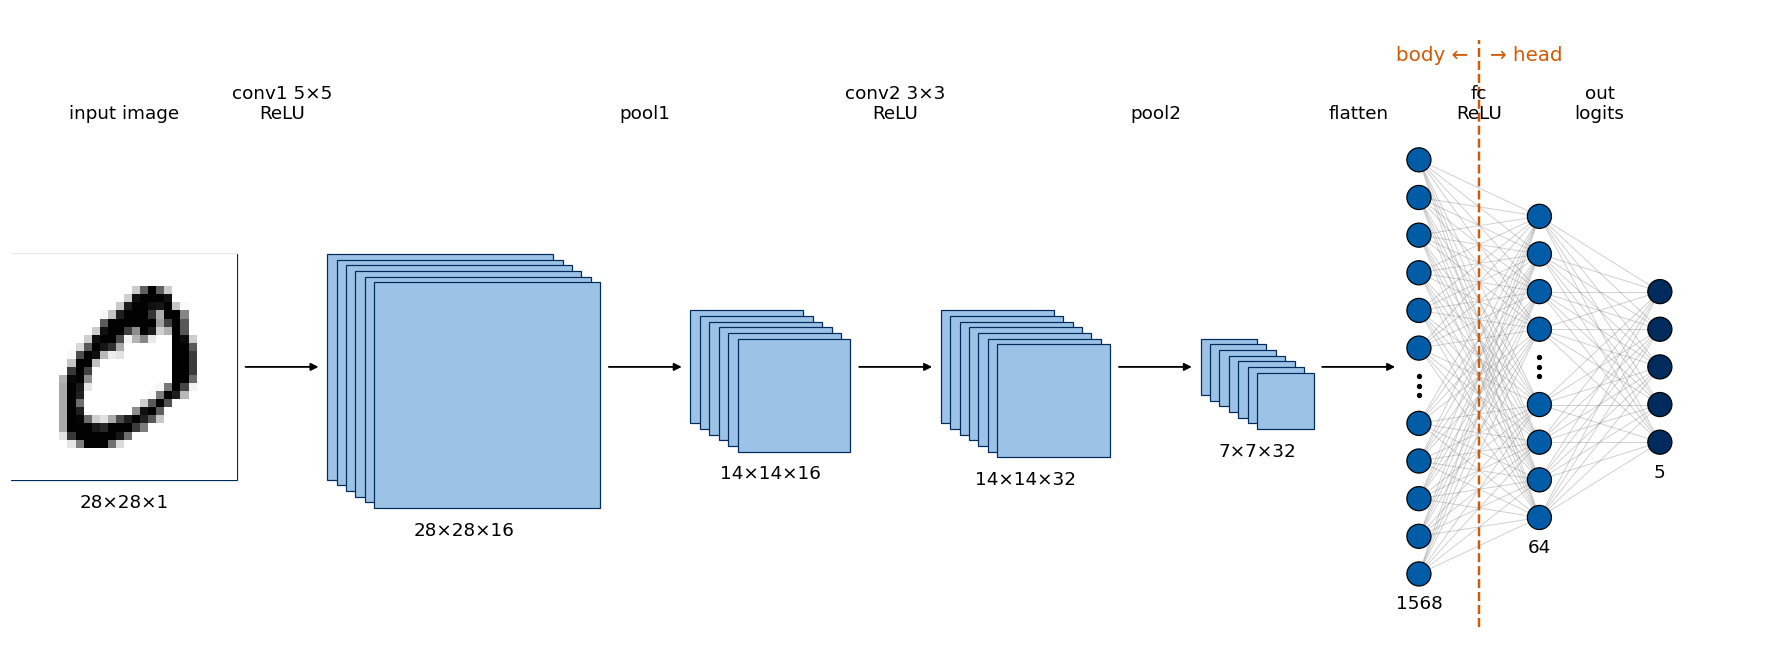

parameters: body 5056, head 100741, total 105797


In [6]:
def smallcnn_stages(n_out=5, extra=False):
    # the stages of SmallCNN for draw_cnn; extra=True adds the dense layer inserted in Section 5.6
    stages = [((28, 28, 1), "input image"), ((28, 28, 16), "conv1 5×5\nReLU"), ((14, 14, 16), "pool1"),
              ((14, 14, 32), "conv2 3×3\nReLU"), ((7, 7, 32), "pool2"), (1568, "flatten"), (64, "fc\nReLU")]
    if extra:
        stages.append((64, "extra\nReLU"))
    return stages + [(n_out, "out\nlogits")]

draw_cnn(smallcnn_stages(), cut=(5, "body", "head"), input_image=Xs_tr[0, 0])
plt.show()
n_body = sum(p.numel() for p in model.body.parameters())
n_head = sum(p.numel() for p in model.head.parameters())
print(f"parameters: body {n_body}, head {n_head}, total {n_body + n_head}")

The package `torchview`, a small Python library that draws PyTorch models, draws the same model from the code instead of from a list written by us. Its function `draw_graph` passes a batch of the given shape through the model, records every module it calls and returns a graph of the data flow; with `expand_nested=True` the modules of `body` and `head` are shown inside two boxes, the two `nn.Sequential` containers. Each module box lists the shapes of its input and output tensors, so the graph is a check of the shapes $(N,1,28,28)\to(N,1568)\to(N,5)$, while our diagram shows the sizes of the maps and of the dense layers at a glance. `torchview` draws with Graphviz, a program that lays out graphs of boxes and arrows, and is not part of the standard Colab installation (`%pip install torchview` installs it); if it is missing, the cell prints a message. The model drawn here is a separate instance created inside `torch.random.fork_rng()`, together with the random input batch, so the random-number generator of the rest of the notebook is not changed.

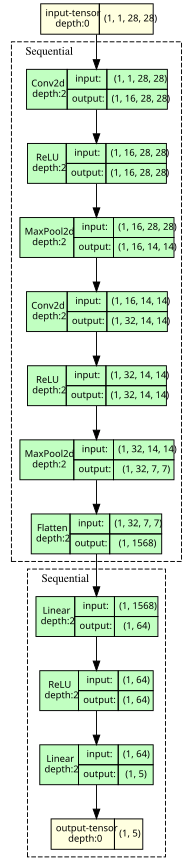

In [7]:
try:
    from torchview import draw_graph
    with torch.random.fork_rng():                        # leaves the global random-number generator unchanged
        graph = draw_graph(SmallCNN(), input_size=(1, 1, 28, 28), expand_nested=True)
    display(graph.visual_graph)
except Exception as err:                                 # torchview or Graphviz not installed
    print("torchview drawing not available:", err)

### 1.3 Training on the source task

Standard supervised training: cross-entropy loss on the logits, Adam with learning rate $10^{-3}$, minibatches of 128 images, one epoch (one pass over the $30\,596$ training images, 239 steps). The minibatch order comes from a NumPy generator with a fixed seed, so Lab 003b sees exactly the same sequence of minibatches.

Two helpers are used for the rest of the notebook: `train_steps` performs a given number of gradient steps on randomly drawn minibatches, and `accuracy` evaluates in chunks of 2000 images under `torch.inference_mode()` (no computational graph is recorded). `model.train()` / `model.eval()` switch layers such as dropout or batch normalisation between their training and evaluation behaviour; our network has none, but calling them is a habit worth having.

In [8]:
def accuracy(model, X, y, chunk=2000):
    # fraction of correctly classified images
    model.eval()
    with torch.inference_mode():
        pred = torch.cat([model(X[i:i + chunk]).argmax(dim=1) for i in range(0, len(X), chunk)])
    return (pred == y).float().mean().item()

def train_epochs(model, X, y, epochs, batch_size, lr, seed):
    # plain training loop: one random permutation of the data per epoch
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    rng = np.random.default_rng(seed)
    n_batches = len(X) // batch_size                  # the last incomplete batch is dropped
    for epoch in range(epochs):
        model.train()
        perm = rng.permutation(len(X))[: n_batches * batch_size].reshape(n_batches, batch_size)
        losses = []
        for idx in perm:
            idx = torch.from_numpy(idx)
            loss = F.cross_entropy(model(X[idx]), y[idx])
            opt.zero_grad(); loss.backward(); opt.step()
            losses.append(loss.item())
        print(f"epoch {epoch + 1}: mean training loss {np.mean(losses):.4f} | test accuracy (digits 0-4) {accuracy(model, Xs_te, ys_te):.4f}")

t0 = time.time()
torch.manual_seed(0)
model = SmallCNN()
train_epochs(model, Xs_tr, ys_tr, epochs=1, batch_size=128, lr=1e-3, seed=0)
acc_source = accuracy(model, Xs_te, ys_te)
print(f"training time: {time.time() - t0:.1f} s | final test accuracy on digits 0-4: {acc_source:.4f}")

epoch 1: mean training loss 0.1997 | test accuracy (digits 0-4) 0.9887


training time: 5.8 s | final test accuracy on digits 0-4: 0.9887


### 1.4 Saving and loading the parameters

What is saved is `model.state_dict()`, an ordered dictionary `{parameter name: tensor}`, e.g. `"body.conv1.weight" → tensor of shape (16, 1, 5, 5)`. It contains the numbers only, not the code of the class. `torch.save` writes it to a file (a zip archive of the tensors).

Loading requires the architecture: we create a *fresh* `SmallCNN` (random parameters) and copy the stored numbers into it with `load_state_dict`. The names and shapes must match; otherwise PyTorch raises an error listing the missing or unexpected keys. `torch.load(..., weights_only=True)` reads tensors only and refuses arbitrary Python objects, which makes loading a file from an unknown source safe.

(The alternative `torch.save(model)` pickles the whole object including a reference to its class; such a file breaks as soon as the class definition is moved or renamed, and is therefore not recommended.)

To confirm that nothing is lost, we compare logits on the whole test set. Before loading, the fresh model gives different logits; after loading, the logits should be **bit-for-bit identical** (`torch.equal`, not just close).

In [9]:
os.makedirs("checkpoints", exist_ok=True)
CKPT = "checkpoints/cnn_digits04_torch.pt"
torch.save(model.state_dict(), CKPT)
print(f"saved {len(model.state_dict())} tensors ({os.path.getsize(CKPT) / 1e3:.0f} kB)")

torch.manual_seed(123)                                  # a different seed: different random parameters
fresh = SmallCNN()
with torch.inference_mode():
    print("fresh model, logits equal to the trained model before loading:", torch.equal(fresh(Xs_te), model(Xs_te)))

state = torch.load(CKPT, weights_only=True)             # dict {name: tensor}
fresh.load_state_dict(state)                            # copies the numbers into the existing parameters
fresh.eval(); model.eval()
with torch.inference_mode():
    same_logits = torch.equal(fresh(Xs_te), model(Xs_te))
assert same_logits
print("after load_state_dict, logits on all", len(Xs_te), "test images identical:", same_logits)
print(f"test accuracy of the reloaded model: {accuracy(fresh, Xs_te, ys_te):.4f}")

saved 8 tensors (427 kB)


fresh model, logits equal to the trained model before loading: False


after load_state_dict, logits on all 5139 test images identical: True


test accuracy of the reloaded model: 0.9887


<hr/>
## 2. Structure of a trained network

### 2.1 Layers, parameter shapes and counts

`print(model)` shows the module tree. `model.named_parameters()` yields every trainable array with its full name. PyTorch shapes follow the convention **(output, input, …)**: a `Conv2d` weight has shape `(out_channels, in_channels, kernel_height, kernel_width)` and its bias `(out_channels,)`, while a `Linear` weight has shape `(out_features, in_features)`, so that $y = x W^{T} + b$, with bias `(out_features,)`.

The number of parameters of a layer is the number of weights plus the number of biases, e.g. for `conv1`: $16\cdot1\cdot5\cdot5+16=416$.

In [10]:
print(model)
print()
print(f"{'parameter':22s} {'shape':>18s} {'count':>8s}")
for name, p in model.named_parameters():
    print(f"{name:22s} {str(tuple(p.shape)):>18s} {p.numel():8d}")
n_total = sum(p.numel() for p in model.parameters())
print(f"{'total':22s} {'':>18s} {n_total:8d}")

# per layer: weights + biases of each module that owns parameters
print()
for lname, layer in model.named_modules():
    own = list(layer.parameters(recurse=False))
    if own:
        print(f"layer {lname:12s} ({type(layer).__name__:6s}): {sum(p.numel() for p in own):6d} parameters")
assert n_total == (16*1*5*5 + 16) + (32*16*3*3 + 32) + (1568*64 + 64) + (64*5 + 5)

SmallCNN(
  (body): Sequential(
    (conv1): Conv2d(1, 16, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (relu1): ReLU()
    (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (relu2): ReLU()
    (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (flatten): Flatten(start_dim=1, end_dim=-1)
  )
  (head): Sequential(
    (fc): Linear(in_features=1568, out_features=64, bias=True)
    (relu3): ReLU()
    (out): Linear(in_features=64, out_features=5, bias=True)
  )
)

parameter                           shape    count
body.conv1.weight           (16, 1, 5, 5)      400
body.conv1.bias                     (16,)       16
body.conv2.weight          (32, 16, 3, 3)     4608
body.conv2.bias                     (32,)       32
head.fc.weight                 (64, 1568)   100352
head.fc.bias                        (64,)       64
head.out.weig

Almost all parameters ($100\,416$ of $105\,797$) sit in the dense layer `head.fc`, which connects all $1568$ outputs of the convolutional part to 64 units; the two convolutional layers together have only $5\,056$, because a kernel is shared over all positions of the image.

### 2.2 Access to a single layer

A layer is reached by attribute access along its name: `model.body.conv1`. Its parameters are `.weight` and `.bias`, tensors with `requires_grad=True`. To use them as plain numbers, call `.detach()` (a tensor without a gradient history, sharing the memory) and `.numpy()`; to modify them directly, do it inside `torch.no_grad()` so that the change is not recorded by automatic differentiation.

In [11]:
conv1 = model.body.conv1                              # the same object as model.body[0]
assert conv1 is model.body[0]
W1 = conv1.weight.detach().numpy()                    # (16, 1, 5, 5)
b1 = conv1.bias.detach().numpy()                      # (16,)
print("conv1 weight:", W1.shape, "| bias:", b1.shape, "| requires_grad:", conv1.weight.requires_grad)
print("kernel 0 (5 x 5):\n", np.round(W1[0, 0], 3))
print("output layer weight:", tuple(model.head.out.weight.shape), "(out_features, in_features) | bias:", np.round(model.head.out.bias.detach().numpy(), 3))

conv1 weight: (16, 1, 5, 5) | bias: (16,) | requires_grad: True
kernel 0 (5 x 5):
 [[ 0.032  0.129 -0.18  -0.223 -0.159]
 [ 0.099  0.027  0.158 -0.063  0.003]
 [-0.012  0.002 -0.17  -0.111 -0.059]
 [ 0.063  0.134  0.178 -0.074 -0.031]
 [ 0.125  0.225  0.022  0.214  0.036]]
output layer weight: (5, 64) (out_features, in_features) | bias: [ 0.     0.088  0.08   0.011 -0.018]


### 2.3 Trainable and frozen parameters

A parameter is **trainable** in PyTorch if `p.requires_grad` is `True`: then `loss.backward()` computes its gradient and an optimiser can change it. Setting `requires_grad=False` **freezes** it. The function below counts both groups; we use it in Section 5. At this point everything is trainable.

In [12]:
def count_params(model):
    # (number of trainable, number of frozen) parameters
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    frozen = sum(p.numel() for p in model.parameters() if not p.requires_grad)
    return trainable, frozen

tr, fr = count_params(model)
print(f"trainable parameters: {tr} | frozen parameters: {fr}")

trainable parameters: 105797 | frozen parameters: 0


For the experiments of Section 5 two more views are useful. `layer_table` lists every layer that owns parameters (the `Conv2d` and `Linear` layers) with its number of parameters and its state, trainable or frozen, read from the `requires_grad` flags; the total line repeats the two counts of `count_params`. `snapshot` stores a copy of every parameter tensor, and `max_change` prints, for every tensor, the largest absolute change since the snapshot,
$$\max_k\,\big|w_k^{\rm after}-w_k^{\rm before}\big| ,$$
where $k$ runs over the entries of the tensor. A value of exactly zero proves that the tensor was not touched, bit for bit; a frozen layer must show zeros, a trained one must not.

In [13]:
def layer_table(model):
    # one row per layer that owns parameters: name, number of parameters, trainable or frozen
    rows = []
    for name, layer in model.named_modules():
        own = list(layer.parameters(recurse=False))            # the layer's own parameters only
        if own:
            flags = {p.requires_grad for p in own}
            state = "trainable" if flags == {True} else ("frozen" if flags == {False} else "mixed")
            rows.append((name, sum(p.numel() for p in own), state))
    print(f"{'layer':12s} {'parameters':>10s}   state")
    for name, n, state in rows:
        print(f"{name:12s} {n:10d}   {state}")
    n_tr = sum(n for _, n, s in rows if s == "trainable")
    print(f"{'total':12s} {sum(n for _, n, _ in rows):10d}   trainable {n_tr}, frozen {sum(n for _, n, _ in rows) - n_tr}")

def snapshot(model):
    # copies of all parameter tensors, to compare with after training
    return {name: p.detach().clone() for name, p in model.named_parameters()}

def max_change(before, model):
    # largest absolute change of every parameter tensor since `before`; exactly 0 means unchanged
    for name, p in model.named_parameters():
        change = f"{(p.detach() - before[name]).abs().max().item():.2e}" if name in before else "new"
        print(f"{name:22s} max|dw| = {change}")

layer_table(model)

layer        parameters   state
body.conv1          416   trainable
body.conv2         4640   trainable
head.fc          100416   trainable
head.out            325   trainable
total            105797   trainable 105797, frozen 0


<hr/>
## 3. Learned kernels and feature maps

### 3.1 First-layer kernels

Each of the 16 kernels of `conv1` is a $5\times5$ array of weights acting on the single input channel, so it can be drawn as a small image. A kernel responds most strongly (largest output before the ReLU) to an image patch that looks like the kernel itself: red weights reward ink, blue weights penalise it. Each kernel is drawn with its own symmetric colour scale $[-\max|w|,\,\max|w|]$, so that its pattern is visible regardless of its overall magnitude.

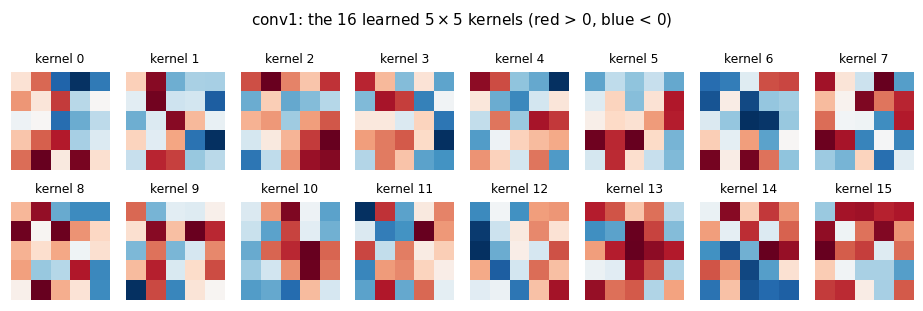

In [14]:
W1 = model.body.conv1.weight.detach().numpy()[:, 0]          # (16, 5, 5): drop the input-channel axis
fig, axs = plt.subplots(2, 8, figsize=(8.5, 3.0))
for k, ax in enumerate(axs.flat):
    v = np.abs(W1[k]).max()
    ax.imshow(W1[k], cmap="RdBu_r", vmin=-v, vmax=v)
    ax.set_title(f"kernel {k}", fontsize=8); noframe(ax)
fig.suptitle("conv1: the 16 learned $5\\times5$ kernels (red > 0, blue < 0)", fontsize=10)
plt.tight_layout(); plt.show()

### 3.2 Feature maps with forward hooks

A **feature map** is the output of one channel of a convolutional layer: an image showing where in the input the corresponding pattern was found. To see it we need the output of an *intermediate* layer, which `model(x)` does not return.

PyTorch provides **forward hooks** for this purpose. `layer.register_forward_hook(fn)` attaches a function that PyTorch calls every time `layer` has computed its output, as `fn(module, inputs, output)`. We store the output in a dictionary. The model code stays untouched; the call returns a *handle*, and `handle.remove()` detaches the hook again (hooks left behind keep running and keep memory).

We hook `relu1` and `relu2`, i.e. we record the maps after the activation, which is what the next layer receives. After `relu1` the recorded tensor has shape `(1, 16, 28, 28)`, 16 maps at full resolution; after `relu2` it has shape `(1, 32, 14, 14)`, 32 maps at half resolution.

In [15]:
features = {}
def save_output(name):
    def hook(module, inputs, output):
        features[name] = output.detach()
    return hook

handles = [model.body.relu1.register_forward_hook(save_output("relu1")),
           model.body.relu2.register_forward_hook(save_output("relu2"))]

i_img = int(np.flatnonzero(ys_te.numpy() == 3)[0])          # the first test image of a 3
x_one = Xs_te[i_img:i_img + 1]                              # (1, 1, 28, 28): a batch of one image
model.eval()
with torch.inference_mode():
    logits = model(x_one)                                   # the hooks fill `features` during this call
for h in handles:
    h.remove()                                              # detach the hooks

assert features["relu1"].shape == (1, 16, 28, 28) and features["relu2"].shape == (1, 32, 14, 14)
print("predicted digit:", logits.argmax().item(), "| true digit:", ys_te[i_img].item())
for k, v in features.items():
    frac = (v > 0).float().mean().item()
    print(f"{k}: shape {tuple(v.shape)}, fraction of positive (active) entries {frac:.3f}")

predicted digit: 3 | true digit: 3
relu1: shape (1, 16, 28, 28), fraction of positive (active) entries 0.645
relu2: shape (1, 32, 14, 14), fraction of positive (active) entries 0.634


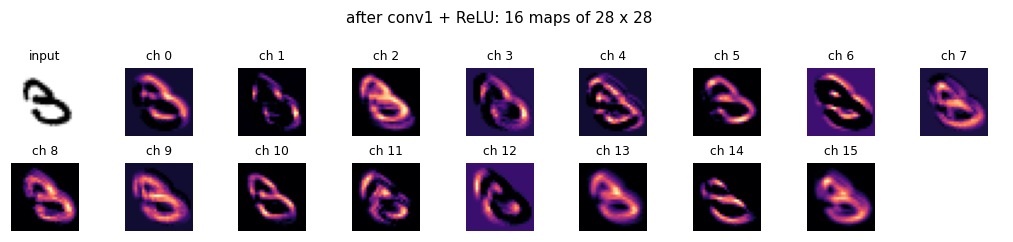

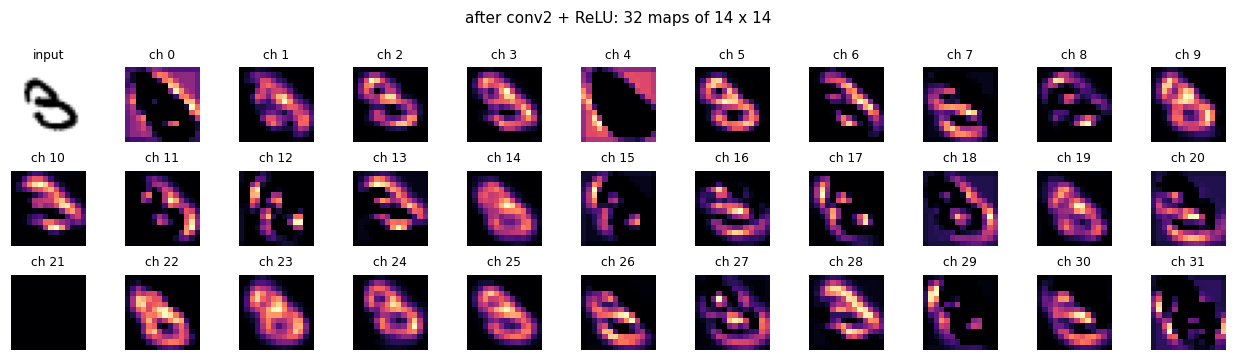

In [16]:
def show_maps(maps, ncols, title, img):
    # maps: (C, H, W); the input image is shown in the first panel
    C = maps.shape[0]
    nrows = int(np.ceil((C + 1) / ncols))
    fig, axs = plt.subplots(nrows, ncols, figsize=(1.05 * ncols, 1.1 * nrows))
    axs = axs.flat
    axs[0].imshow(img, cmap="gray_r"); axs[0].set_title("input", fontsize=8)
    for c in range(C):
        axs[c + 1].imshow(maps[c], cmap="magma"); axs[c + 1].set_title(f"ch {c}", fontsize=8)
    for ax in axs: noframe(ax)
    fig.suptitle(title, fontsize=10); plt.tight_layout(); plt.show()

img = x_one[0, 0].numpy()
show_maps(features["relu1"][0].numpy(), 9, "after conv1 + ReLU: 16 maps of 28 x 28", img)
show_maps(features["relu2"][0].numpy(), 11, "after conv2 + ReLU: 32 maps of 14 x 14", img)

Most first-layer maps are filtered copies of the digit. In several of them only one side of the strokes, or only the strokes of one orientation, light up: a kernel with adjacent positive (red) and negative (blue) regions in Section 3.1 responds to a change of brightness in one direction, i.e. it is an oriented edge detector. Other maps respond to the background next to the ink. Second-layer maps have half the resolution, and each channel combines all 16 first-layer maps; the channels respond to more specific configurations, such as strokes of one direction in one part of the digit, and some are sparse for this image. This is the hierarchy of Lecture 4: local, generic patterns (edges, stroke directions) in the first layer, and combinations of them, more specific to the task, deeper in the network.

<hr/>
## 4. Model surgery

All operations of this section create new models from pieces of the trained one. One rule matters throughout: **assigning a module to a new model does not copy it**. `nn.Sequential(model.body, ...)` contains *the same* `body` object; training the new model would also change `model`. Use `copy.deepcopy` whenever the original must stay intact.

### 4.1 Cutting the network: a feature extractor

`model.body` alone maps images to feature vectors of 1568 numbers, `(N, 1, 28, 28) → (N, 1568)`. An `nn.Sequential` can be sliced like a list: `model.body[:6]` stops before the flattening and returns the 32 feature maps, `(N, 32, 7, 7)`; `model.head[:2]` (dense layer + ReLU) applied to the body's output gives the 64 features of the next level, `(N, 64)`.

We compute both kinds of features for 2000 test images of the source digits 0–4 and 2000 of the unseen digits 5–9 and count active units (positive after the ReLU). A unit that is zero for every image ("dead" unit) carries no information about these images. Features that stay active and varied for 5–9 are candidates for re-use in Section 5.

In [17]:
extractor = model.body                                      # (N,1,28,28) -> (N,1568); shares the parameters with `model`
conv_maps = model.body[:6]                                  # conv1 ... pool2: (N,1,28,28) -> (N,32,7,7)
dense_part = model.head[:2]                                 # fc + ReLU:       (N,1568) -> (N,64)
model.eval()
with torch.inference_mode():
    m_src = conv_maps(Xs_te[:2000])                         # (2000, 32, 7, 7)
    feats = {"digits 0-4 (seen)  ": extractor(Xs_te[:2000]),     # (2000, 1568)
             "digits 5-9 (unseen)": extractor(Xt_te[:2000])}
    dense = {k: dense_part(f) for k, f in feats.items()}    # (2000, 64)
assert m_src.shape == (2000, 32, 7, 7) and feats["digits 0-4 (seen)  "].shape == (2000, 1568)
print("feature maps:", tuple(m_src.shape), "| body features:", tuple(feats["digits 0-4 (seen)  "].shape),
      "| dense features:", tuple(dense["digits 0-4 (seen)  "].shape))

def activity(f):
    active = (f > 0).float()
    return active.mean().item(), int((active.sum(0) == 0).sum())

for k in feats:
    a1, d1 = activity(feats[k]); a2, d2 = activity(dense[k])
    print(f"{k}: body features: active fraction {a1:.3f}, never active {d1:4d} of 1568 | "
          f"dense features: active fraction {a2:.3f}, never active {d2:2d} of 64")
f_tgt = feats["digits 5-9 (unseen)"]

feature maps: (2000, 32, 7, 7) | body features: (2000, 1568) | dense features: (2000, 64)
digits 0-4 (seen)  : body features: active fraction 0.762, never active   51 of 1568 | dense features: active fraction 0.531, never active 20 of 64
digits 5-9 (unseen): body features: active fraction 0.767, never active   48 of 1568 | dense features: active fraction 0.566, never active 20 of 64


### 4.2 Trained body, new head

For the digits 5–9 we need a network with the trained body and a *new*, randomly initialised head with 5 outputs. We create a fresh `SmallCNN(n_classes=5)` and copy the body's numbers with `new.body.load_state_dict(model.body.state_dict())`. This copies values: the new body is independent of `model`.

The new body should give the same feature vectors as the trained one, and the cell confirms it. The new head is random, so the accuracy on the digits 5–9 should be near chance level, $1/5=0.2$.

In [18]:
torch.manual_seed(1)
new = SmallCNN(n_classes=5)
new.body.load_state_dict(model.body.state_dict())          # copy the trained body; the head stays random
new.eval()
with torch.inference_mode():
    assert torch.equal(new.body(Xt_te[:2000]), f_tgt)      # identical features
assert new.body.conv1.weight.data_ptr() != model.body.conv1.weight.data_ptr()   # separate memory: no sharing
print("new body gives identical features:", True)
print(f"accuracy on digits 5-9 with the untrained head: {accuracy(new, Xt_te, yt_te):.3f} (chance level 0.2)")

# the pitfall: building a model from the *same* module object shares the parameters
shared = nn.Sequential(model.body, nn.Linear(1568, 5))
print("nn.Sequential(model.body, ...) shares model.body:", shared[0] is model.body,
      "| after copy.deepcopy:", copy.deepcopy(model.body) is model.body)

new body gives identical features: True


accuracy on digits 5-9 with the untrained head: 0.200 (chance level 0.2)
nn.Sequential(model.body, ...) shares model.body: True | after copy.deepcopy: False


### 4.3 Inserting a layer

We insert an extra dense layer, $64\to64$ followed by a ReLU, inside the head, between `relu3` and `out`. If it is initialised as the identity ($W=I$, $b=0$), the network computes exactly the same function as before: its input $h$ is non-negative (it comes out of a ReLU), so $\mathrm{ReLU}(Ih+0)=h$. This is a useful way to enlarge a trained network without losing what it knows; training can then move the new layer away from the identity.

Shapes: body `(N,1568)` → fc, ReLU `(N,64)` → extra, ReLU `(N,64)` → out `(N,5)`. The parameter count grows by $64\cdot64+64=4160$.

In [19]:
extra = nn.Linear(64, 64)
with torch.no_grad():                                       # manual assignment: not recorded by autograd
    extra.weight.copy_(torch.eye(64))
    extra.bias.zero_()

deeper = nn.Sequential(OrderedDict([
    ("body", copy.deepcopy(model.body)),                    # copies: `model` stays untouched
    ("fc", copy.deepcopy(model.head.fc)),
    ("relu3", nn.ReLU()),
    ("extra", extra),                                       # the inserted layer
    ("extra_relu", nn.ReLU()),
    ("out", copy.deepcopy(model.head.out)),
]))
deeper.eval()
with torch.inference_mode():
    same = torch.allclose(deeper(Xs_te), model(Xs_te))
assert same
print("deeper model, logits equal to the original:", same)
print("parameters: original", sum(p.numel() for p in model.parameters()),
      "| deeper", sum(p.numel() for p in deeper.parameters()))

deeper model, logits equal to the original: True
parameters: original 105797 | deeper 109957


### 4.4 Replacing a layer

A layer can be exchanged by assigning a new module to its name, `net.body.pool1 = nn.AvgPool2d(2)`. The replacement must produce an output of the same shape, otherwise the next layer fails. The rest of the network was trained for the *old* layer, so its accuracy changes. We try two replacements on copies of the trained model. The first replaces max-pooling by average-pooling in `pool1`, which gives the same shape `(N,16,14,14)` but different numbers. The second replaces `conv1` by a new, randomly initialised convolution of the same shape, so that everything after it receives inputs it was never trained on.

In [20]:
net_avg = copy.deepcopy(model)
net_avg.body.pool1 = nn.AvgPool2d(2)                        # replace by name
torch.manual_seed(2)
net_rnd = copy.deepcopy(model)
net_rnd.body.conv1 = nn.Conv2d(1, 16, kernel_size=5, padding=2)   # fresh random kernels, same shapes
print(net_avg.body.pool1, "|", net_rnd.body.conv1)
print(f"test accuracy (digits 0-4): original {accuracy(model, Xs_te, ys_te):.4f} | "
      f"pool1 -> average {accuracy(net_avg, Xs_te, ys_te):.4f} | conv1 re-initialised {accuracy(net_rnd, Xs_te, ys_te):.4f}")

AvgPool2d(kernel_size=2, stride=2, padding=0) | Conv2d(1, 16, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))


test accuracy (digits 0-4): original 0.9887 | pool1 -> average 0.9889 | conv1 re-initialised 0.5600


Average pooling changes the numbers passed on but keeps their meaning (the same channels, the same positions), so the accuracy hardly changes. A re-initialised first layer destroys the meaning of all 16 channels for the layers after it, and the accuracy falls far: a trained network is a chain in which each layer is adapted to the layers before it.

<hr/>
## 5. Freezing and transfer learning

### 5.1 The target task with few labels

The new task is to classify the digits 5–9, with only a few labelled images, $n$ per class. **Transfer learning** re-uses the body trained on 0–4: strokes, edges and loops are common to all digits, so the convolutional features of Section 4.1 may also help for 5–9. We compare three strategies with the same number of gradient steps in total (300, minibatches of $\min(64, 5n)$ images, Adam):

| | initial body | trained parameters | steps | learning rate |
|---|---|---|---|---|
| (a) random initialisation | random | all | 300 | $10^{-3}$ |
| (b) frozen body | trained on 0–4 | head only | 200 | $10^{-3}$ |
| (c) fine-tuning | the result of (b) | all | +100 | body $10^{-4}$, head $3\cdot10^{-4}$ |

In (c) the learning rate is smaller: the body is already trained, and large steps driven by a few hundred images would overwrite it (and overfit). The labelled subset is drawn with a NumPy generator (`seed`), class by class, so Lab 003b uses exactly the same images. Below we first run the three strategies in detail for $n=100$ images per class (500 labelled images), and in Section 5.5 for several $n$.

In [21]:
def labelled_subset(n_per_class, seed):
    # n_per_class images of each target class, drawn from the pool without replacement
    rng = np.random.default_rng(seed)
    y = yt_pool.numpy()
    idx = np.concatenate([rng.choice(np.flatnonzero(y == c), n_per_class, replace=False) for c in range(5)])
    return Xt_pool[idx], yt_pool[idx]

def train_steps(model, opt, X, y, steps, seed):
    # `steps` Adam steps on minibatches of min(64, len(X)) images drawn at random
    rng = np.random.default_rng(seed)
    bs = min(64, len(X))
    model.train()
    for _ in range(steps):
        idx = torch.from_numpy(rng.choice(len(X), bs, replace=False))
        loss = F.cross_entropy(model(X[idx]), y[idx])
        opt.zero_grad(); loss.backward(); opt.step()
    return loss.item()

def transfer_model(seed):
    # trained body (copied), new random head with 5 outputs
    torch.manual_seed(seed)
    m = SmallCNN(5)
    m.body.load_state_dict(model.body.state_dict())
    return m

X_lab, y_lab = labelled_subset(100, seed=0)
assert X_lab.shape == (500, 1, 28, 28) and torch.equal(torch.bincount(y_lab), torch.full((5,), 100))
print("labelled set:", tuple(X_lab.shape), "| images per class:", torch.bincount(y_lab).tolist())

labelled set: (500, 1, 28, 28) | images per class: [100, 100, 100, 100, 100]


### 5.2 Training from a random initialisation

In strategy (a) all 105 797 parameters start random and are trained on the 500 labelled images only. This is the baseline against which transfer is measured.

In [22]:
torch.manual_seed(10)
net_a = SmallCNN(5)
opt = torch.optim.Adam(net_a.parameters(), lr=1e-3)
last = train_steps(net_a, opt, X_lab, y_lab, steps=300, seed=0)
acc_a = accuracy(net_a, Xt_te, yt_te)
print(f"(a) last minibatch loss {last:.4f} | test accuracy on digits 5-9: {acc_a:.4f}")

(a) last minibatch loss 0.0121 | test accuracy on digits 5-9: 0.9317


### 5.3 Frozen body with a new head

Strategy (b) keeps the trained body fixed. Freezing in PyTorch has two parts. First, `p.requires_grad_(False)` is set for every parameter of the body, so that `backward()` no longer computes their gradients (`p.grad` stays `None`), which also saves computation. Second, the optimiser receives only the head's parameters, `torch.optim.Adam(net.head.parameters())`, so it cannot change anything else.

Either part alone would already keep the body fixed for plain Adam; using both is the safe habit. (One caution for other networks: batch normalisation layers update their running statistics in `train()` mode even when their parameters are frozen; a frozen body containing them is put in `eval()` mode.)

To make sure the freezing works, we copy the body's parameters before training and assert afterwards that they are bit-for-bit unchanged, while the head did change.

In [23]:
net_b = transfer_model(seed=10)
for p in net_b.body.parameters():
    p.requires_grad_(False)                                   # freeze the body
tr, fr = count_params(net_b)
print(f"trainable parameters: {tr} (head) | frozen parameters: {fr} (body)")
assert tr == (1568 * 64 + 64) + (64 * 5 + 5)

body_before = copy.deepcopy(net_b.body.state_dict())          # snapshot for the check
head_before = copy.deepcopy(net_b.head.state_dict())
opt = torch.optim.Adam(net_b.head.parameters(), lr=1e-3)      # the optimiser sees only the head
last = train_steps(net_b, opt, X_lab, y_lab, steps=200, seed=0)

body_after, head_after = net_b.body.state_dict(), net_b.head.state_dict()
assert all(torch.equal(body_before[k], body_after[k]) for k in body_before), "frozen body changed!"
assert not torch.equal(head_before["fc.weight"], head_after["fc.weight"])
print("body parameters unchanged:", True, "| head changed:", True, "| body.conv1.weight.grad:", net_b.body.conv1.weight.grad)
acc_b = accuracy(net_b, Xt_te, yt_te)
print(f"(b) last minibatch loss {last:.4f} | test accuracy on digits 5-9: {acc_b:.4f}")

trainable parameters: 100741 (head) | frozen parameters: 5056 (body)


body parameters unchanged: True | head changed: True | body.conv1.weight.grad: None


(b) last minibatch loss 0.0520 | test accuracy on digits 5-9: 0.9461


The drawing shows the state of network (b): the hatched grey layers are frozen, the blue layers with orange connections are trained. The table lists the same split layer by layer. To see what training actually did, we compare every parameter tensor with its value before training: the starting network is rebuilt with `transfer_model(seed=10)`, which gives exactly the same initial parameters as for `net_b` (inside `torch.random.fork_rng()`, so that the generator of the rest of the notebook is not disturbed). The convolutional layers must show $\max|\Delta w| = 0$ exactly, the head must have moved.

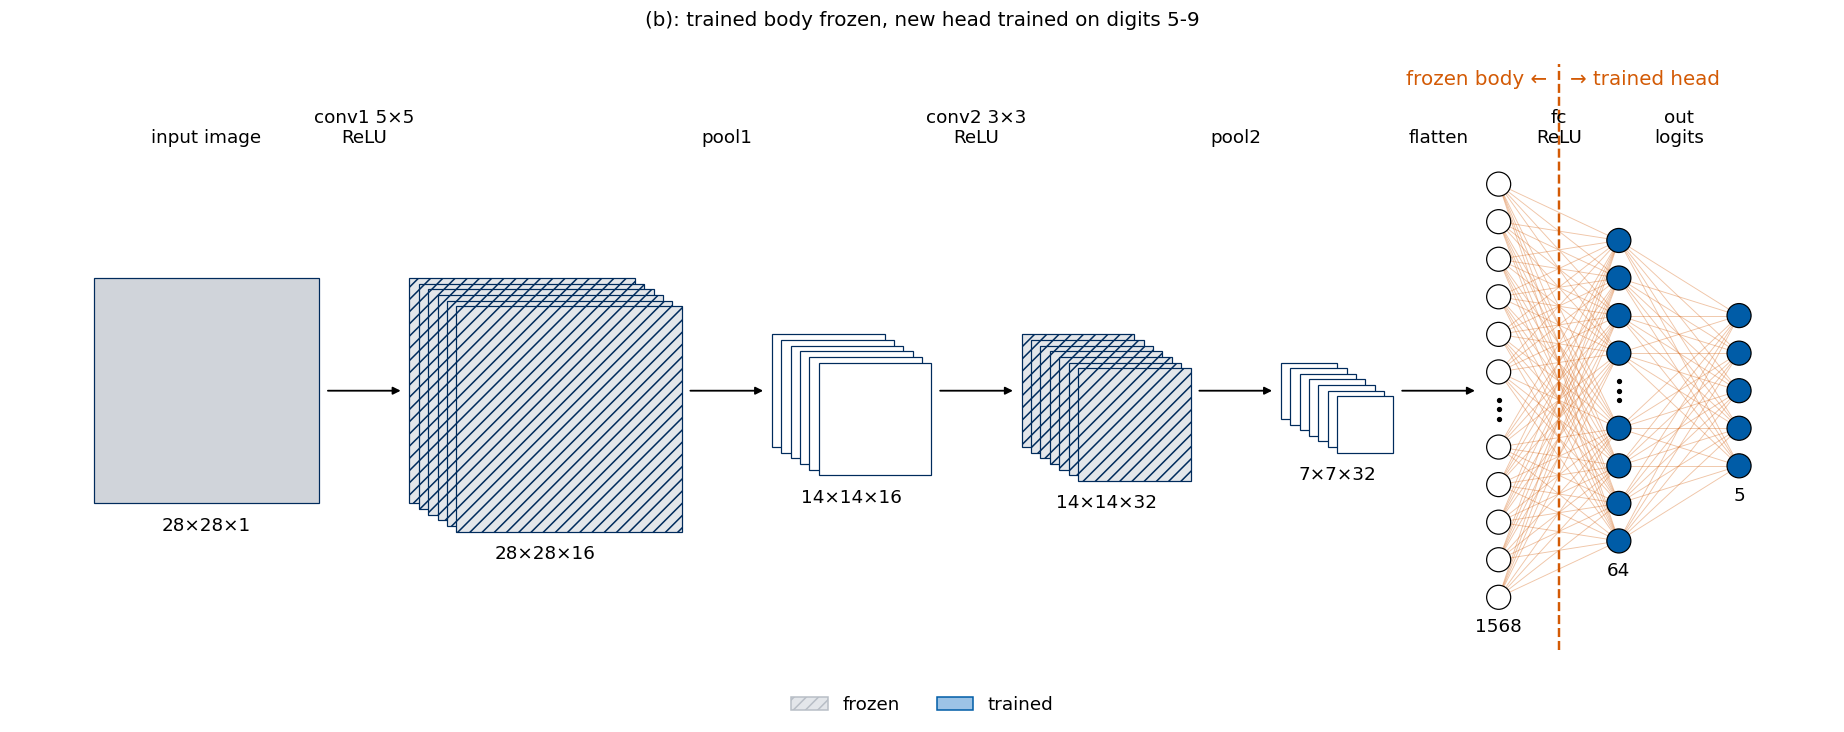

layer        parameters   state
body.conv1          416   frozen
body.conv2         4640   frozen
head.fc          100416   trainable
head.out            325   trainable
total            105797   trainable 100741, frozen 5056
body.conv1.weight      max|dw| = 0.00e+00
body.conv1.bias        max|dw| = 0.00e+00
body.conv2.weight      max|dw| = 0.00e+00
body.conv2.bias        max|dw| = 0.00e+00
head.fc.weight         max|dw| = 1.04e-01
head.fc.bias           max|dw| = 1.78e-02
head.out.weight        max|dw| = 8.82e-02
head.out.bias          max|dw| = 1.01e-02


In [24]:
FROZEN_BODY = [None, "frozen", None, "frozen", None, None, "trained", "trained"]
draw_cnn(smallcnn_stages(), status=FROZEN_BODY, cut=(5, "frozen body", "trained head"),
         title="(b): trained body frozen, new head trained on digits 5-9")
plt.show()
layer_table(net_b)
with torch.random.fork_rng():
    start_b = transfer_model(seed=10)                           # net_b before training
max_change(snapshot(start_b), net_b)

The four parameter tensors of the convolutional body show $\max|\Delta w| = 0$ exactly: 200 training steps did not change a single bit of them, while the weights of the head moved by up to 0.10. Freezing is therefore not an approximation; the frozen layers are left exactly as they were.

The place of the cut matters. Section 3 suggested that early layers compute generic patterns and later layers task-specific ones. We test this directly by cutting one layer later: the trained dense layer `head.fc` is kept frozen as well, and only a new output layer (325 parameters) is trained on the same 500 images, with the same 200 steps.

In [25]:
net_b2 = copy.deepcopy(model)                                  # trained body and trained dense layer
torch.manual_seed(10)
net_b2.head.out = nn.Linear(64, 5)                             # new output layer
for name, p in net_b2.named_parameters():
    p.requires_grad_(name.startswith("head.out"))              # freeze everything except the output layer
print("trainable / frozen parameters:", count_params(net_b2))
train_steps(net_b2, torch.optim.Adam(net_b2.head.out.parameters(), lr=1e-3), X_lab, y_lab, steps=200, seed=0)
acc_b2 = accuracy(net_b2, Xt_te, yt_te)
print(f"test accuracy on digits 5-9: cut after the convolutional body {acc_b:.4f} | cut after the dense layer {acc_b2:.4f}")

trainable / frozen parameters: (325, 105472)


test accuracy on digits 5-9: cut after the convolutional body 0.9461 | cut after the dense layer 0.6589


In the drawing of this variant only the output layer is trained: it is a new layer (green), and everything before it, including the dense layer `fc` trained on the digits 0–4, is frozen.

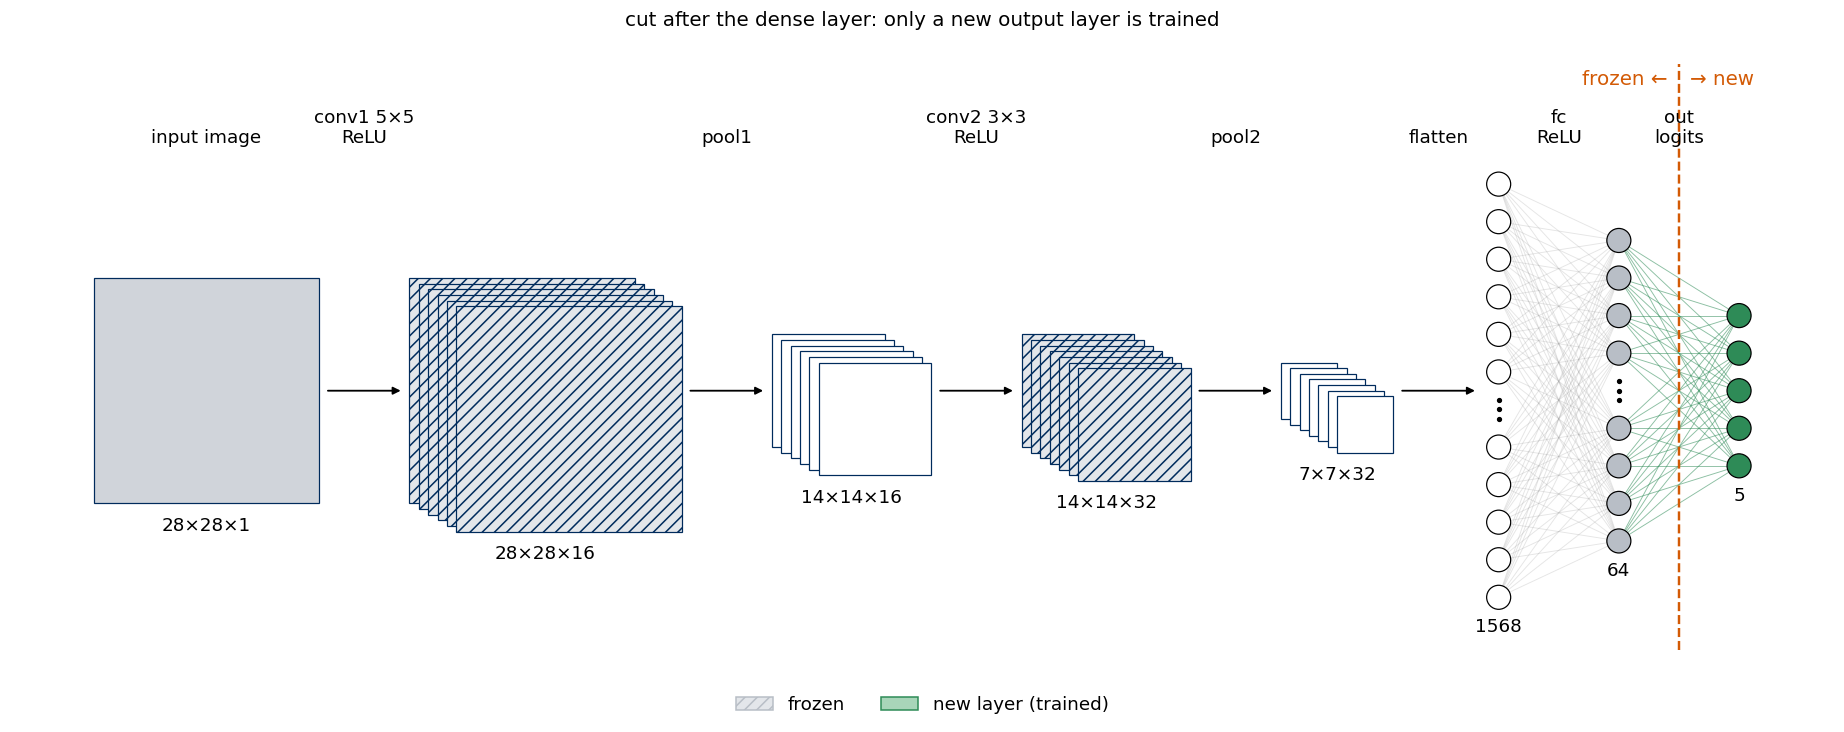

layer        parameters   state
body.conv1          416   frozen
body.conv2         4640   frozen
head.fc          100416   frozen
head.out            325   trainable
total            105797   trainable 325, frozen 105472


In [26]:
draw_cnn(smallcnn_stages(), status=[None, "frozen", None, "frozen", None, None, "frozen", "new"], cut=(6, "frozen", "new"),
         title="cut after the dense layer: only a new output layer is trained")
plt.show()
layer_table(net_b2)

### 5.4 Fine-tuning with a smaller learning rate

Strategy (c) continues from the result of (b): we unfreeze the body (`requires_grad_(True)`) and train all parameters for 100 more steps. **Parameter groups** give different parts of the network different hyperparameters within one optimiser: a list of dictionaries, each with its own `"params"` and `"lr"`. Here the body moves with $10^{-4}$ and the head with $3\cdot10^{-4}$.

In [27]:
net_c = copy.deepcopy(net_b)                                   # (b) stays available
for p in net_c.body.parameters():
    p.requires_grad_(True)                                     # unfreeze
print("trainable / frozen parameters:", count_params(net_c))

opt = torch.optim.Adam([
    {"params": net_c.body.parameters(), "lr": 1e-4},           # group 0: body, small steps
    {"params": net_c.head.parameters(), "lr": 3e-4},           # group 1: head
])
print("learning rates of the parameter groups:", [g["lr"] for g in opt.param_groups])
last = train_steps(net_c, opt, X_lab, y_lab, steps=100, seed=1)
assert not torch.equal(net_c.body.conv1.weight, net_b.body.conv1.weight)   # the body did move this time
acc_c = accuracy(net_c, Xt_te, yt_te)
print(f"(c) last minibatch loss {last:.4f} | test accuracy on digits 5-9: {acc_c:.4f}")
print(f"\nn = 100 images per class: (a) {acc_a:.4f} | (b) {acc_b:.4f} | (c) {acc_c:.4f}")

trainable / frozen parameters: (105797, 0)
learning rates of the parameter groups: [0.0001, 0.0003]


(c) last minibatch loss 0.0074 | test accuracy on digits 5-9: 0.9475

n = 100 images per class: (a) 0.9317 | (b) 0.9461 | (c) 0.9475


In (c) every layer is trained again, the body with the smaller learning rate. The changes relative to the starting point, the network (b), show that this time the body moved as well.

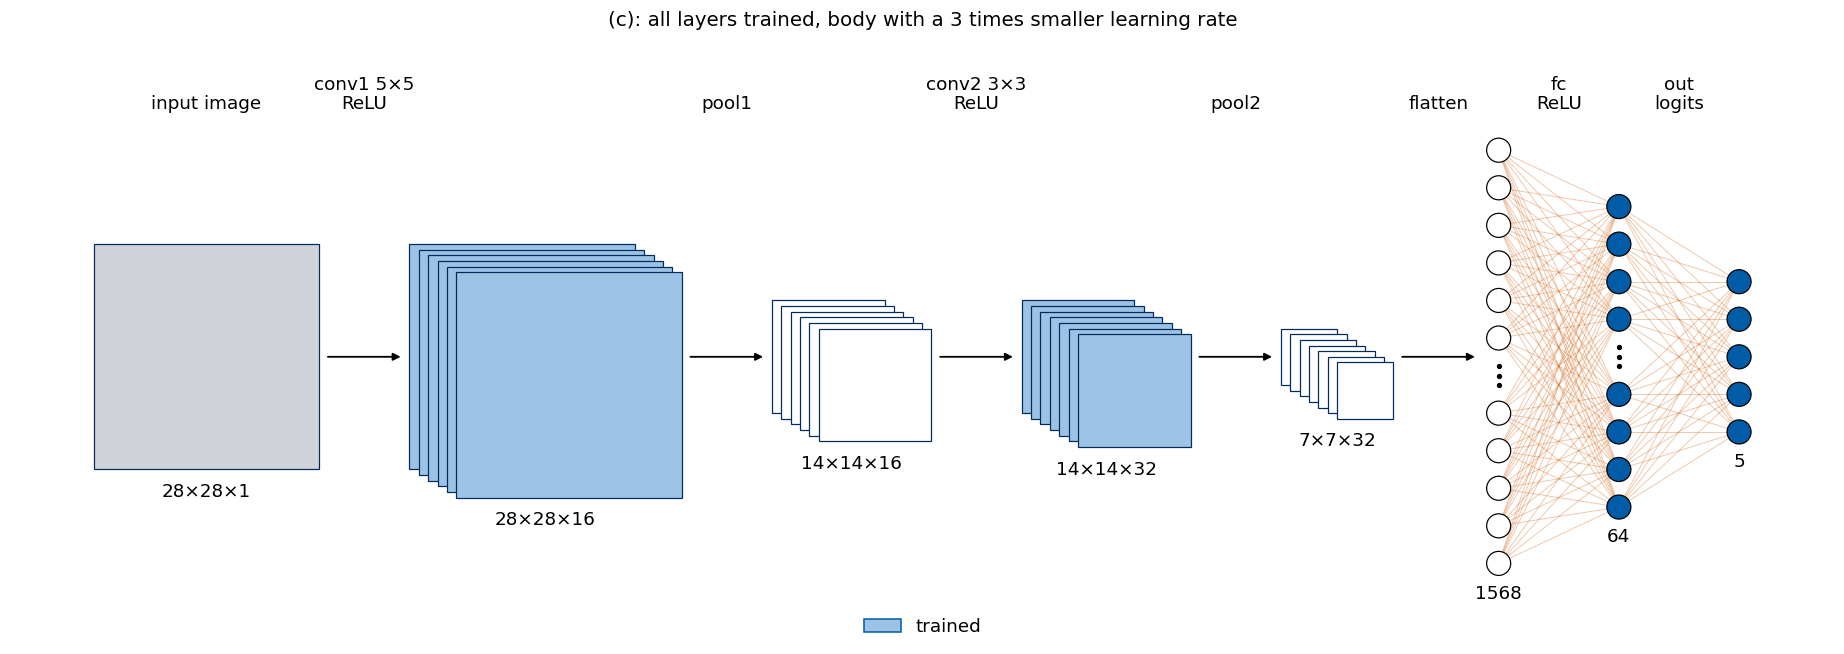

layer        parameters   state
body.conv1          416   trainable
body.conv2         4640   trainable
head.fc          100416   trainable
head.out            325   trainable
total            105797   trainable 105797, frozen 0
body.conv1.weight      max|dw| = 7.99e-03
body.conv1.bias        max|dw| = 4.59e-03
body.conv2.weight      max|dw| = 6.65e-03
body.conv2.bias        max|dw| = 3.37e-03
head.fc.weight         max|dw| = 2.29e-02
head.fc.bias           max|dw| = 1.84e-03
head.out.weight        max|dw| = 1.59e-02
head.out.bias          max|dw| = 1.13e-03


In [28]:
draw_cnn(smallcnn_stages(), status=[None, "trained", None, "trained", None, None, "trained", "trained"],
         title="(c): all layers trained, body with a 3 times smaller learning rate")
plt.show()
layer_table(net_c)
max_change(snapshot(net_b), net_c)

This time all eight tensors changed. The largest changes of the two kernels of the body, $8.0\cdot10^{-3}$ and $6.7\cdot10^{-3}$, are smaller than those of the head, $2.3\cdot10^{-2}$ and $1.6\cdot10^{-2}$ for the two weight matrices, as expected from the three times smaller learning rate of the body.

### 5.5 Dependence on the number of labelled images

A single value of $n$ does not show when transfer pays off. We therefore repeat (a), (b), (c) for $n\in\{10, 30, 100, 300\}$ images per class, i.e. 50 to 1500 labelled images, each with 3 different labelled subsets (seeds 0, 1, 2). The figure shows the mean test accuracy on all 4861 test images of the digits 5–9; the error bars are the standard deviation over the 3 subsets.

In [29]:
def run_all(n_per_class, seed):
    X, y = labelled_subset(n_per_class, seed)
    torch.manual_seed(100 + seed)                               # (a) random initialisation
    m = SmallCNN(5)
    train_steps(m, torch.optim.Adam(m.parameters(), lr=1e-3), X, y, 300, seed)
    acc = [accuracy(m, Xt_te, yt_te)]
    m = transfer_model(100 + seed)                              # (b) frozen body
    for p in m.body.parameters(): p.requires_grad_(False)
    train_steps(m, torch.optim.Adam(m.head.parameters(), lr=1e-3), X, y, 200, seed)
    acc.append(accuracy(m, Xt_te, yt_te))
    for p in m.body.parameters(): p.requires_grad_(True)       # (c) fine-tuning, continues from (b)
    opt = torch.optim.Adam([{"params": m.body.parameters(), "lr": 1e-4}, {"params": m.head.parameters(), "lr": 3e-4}])
    train_steps(m, opt, X, y, 100, seed + 1000)
    acc.append(accuracy(m, Xt_te, yt_te))
    return acc

t0 = time.time()
N_PER_CLASS = [10, 30, 100, 300]
SEEDS = [0, 1, 2]
acc = np.array([[run_all(n, s) for s in SEEDS] for n in N_PER_CLASS])   # (n values, seeds, strategies)
print(f"sweep time: {time.time() - t0:.0f} s\n")
print("test accuracy on digits 5-9, mean ± std over 3 labelled subsets")
print(f"{'n per class':>12s} {'(a) random init':>18s} {'(b) frozen body':>18s} {'(c) fine-tuned':>18s}")
for i, n in enumerate(N_PER_CLASS):
    print(f"{n:12d} " + " ".join(f"{acc[i, :, j].mean():11.4f} ± {acc[i, :, j].std():.4f}" for j in range(3)))

sweep time: 114 s

test accuracy on digits 5-9, mean ± std over 3 labelled subsets
 n per class    (a) random init    (b) frozen body     (c) fine-tuned
          10      0.8542 ± 0.0146      0.8709 ± 0.0213      0.8686 ± 0.0213
          30      0.9085 ± 0.0116      0.9226 ± 0.0062      0.9223 ± 0.0065
         100      0.9423 ± 0.0007      0.9504 ± 0.0017      0.9526 ± 0.0026
         300      0.9717 ± 0.0022      0.9625 ± 0.0047      0.9689 ± 0.0016


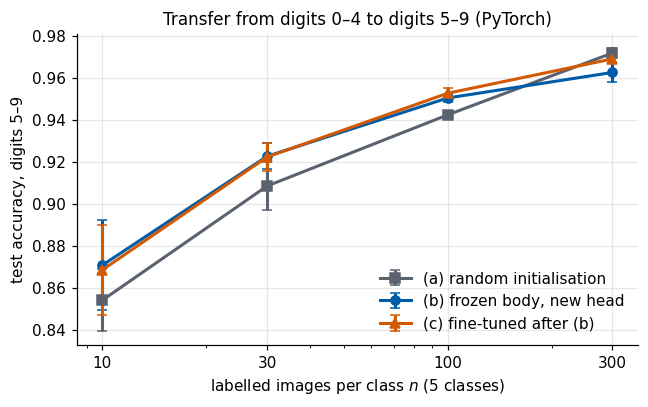

In [30]:
labels = ["(a) random initialisation", "(b) frozen body, new head", "(c) fine-tuned after (b)"]
colors, markers = [UJGray, UJBlue, DSOrange], ["s", "o", "^"]
fig, ax = plt.subplots(figsize=(6, 3.8))
for j in range(3):
    m, s = acc[:, :, j].mean(1), acc[:, :, j].std(1)
    ax.errorbar(N_PER_CLASS, m, yerr=s, color=colors[j], marker=markers[j], ms=6, lw=2, capsize=3, label=labels[j])
ax.set_xscale("log"); ax.set_xticks(N_PER_CLASS); ax.set_xticklabels(N_PER_CLASS)
ax.set_xlabel("labelled images per class $n$ (5 classes)")
ax.set_ylabel("test accuracy, digits 5–9")
ax.set_title("Transfer from digits 0–4 to digits 5–9 (PyTorch)")
ax.grid(alpha=0.3); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

For $n=30$ and $n=100$ images per class the trained body helps: (b) and (c) lie above (a) by more than the spread over the labelled subsets. For $n=10$ the mean is also higher, but the spread over subsets is of the same size as the difference. At $n=300$ the network trained from a random initialisation catches up: with enough labels it learns features for 5–9 by itself, while the frozen body keeps the features learned for 0–4. Fine-tuning (c) gives at most a small gain over (b) with these 100 extra steps.

The gains from transfer are modest here because the target task is easy: a small CNN trained from a random initialisation on 50 images already classifies most test digits correctly. The choice of the cut (Section 5.3) mattered much more: a frozen dense layer trained on 0–4 left far fewer correctly classified digits than the frozen convolutional body. Generic early features transfer; task-specific late features do not.

### 5.6 Training an inserted layer

Section 4.3 inserted a dense layer into a trained network without changing the function it computes. Here we take the next step and train such a layer. We start from network (b), whose head was trained on the digits 5–9, insert the layer `extra` ($64\to64$, followed by a ReLU) between `fc` and `out`, and initialise it as the identity, $W=I$, $b=0$, so that the network still computes exactly the same function; the cell checks that the logits on the test images are unchanged. Then we train only the new layer and the output layer. The body and `fc` are frozen with `requires_grad_(False)`, and the optimiser receives only the parameters that still require a gradient, `[p for p in net_d.parameters() if p.requires_grad]`. Starting from the identity means that training begins at the accuracy of (b) and can only build on it; a randomly initialised extra layer would first destroy the function that the head has learned.

layer        parameters   state
body.conv1          416   frozen
body.conv2         4640   frozen
head.fc          100416   frozen
head.extra         4160   trainable
head.out            325   trainable
total            109957   trainable 4485, frozen 105472


body.conv1.weight      max|dw| = 0.00e+00
body.conv1.bias        max|dw| = 0.00e+00
body.conv2.weight      max|dw| = 0.00e+00
body.conv2.bias        max|dw| = 0.00e+00
head.fc.weight         max|dw| = 0.00e+00
head.fc.bias           max|dw| = 0.00e+00
head.extra.weight      max|dw| = 5.22e-02
head.extra.bias        max|dw| = 1.25e-02
head.out.weight        max|dw| = 5.31e-02
head.out.bias          max|dw| = 4.56e-03


accuracy on digits 5-9: (b) 0.9461 | identity layer inserted 0.9461 | after training it 0.9482


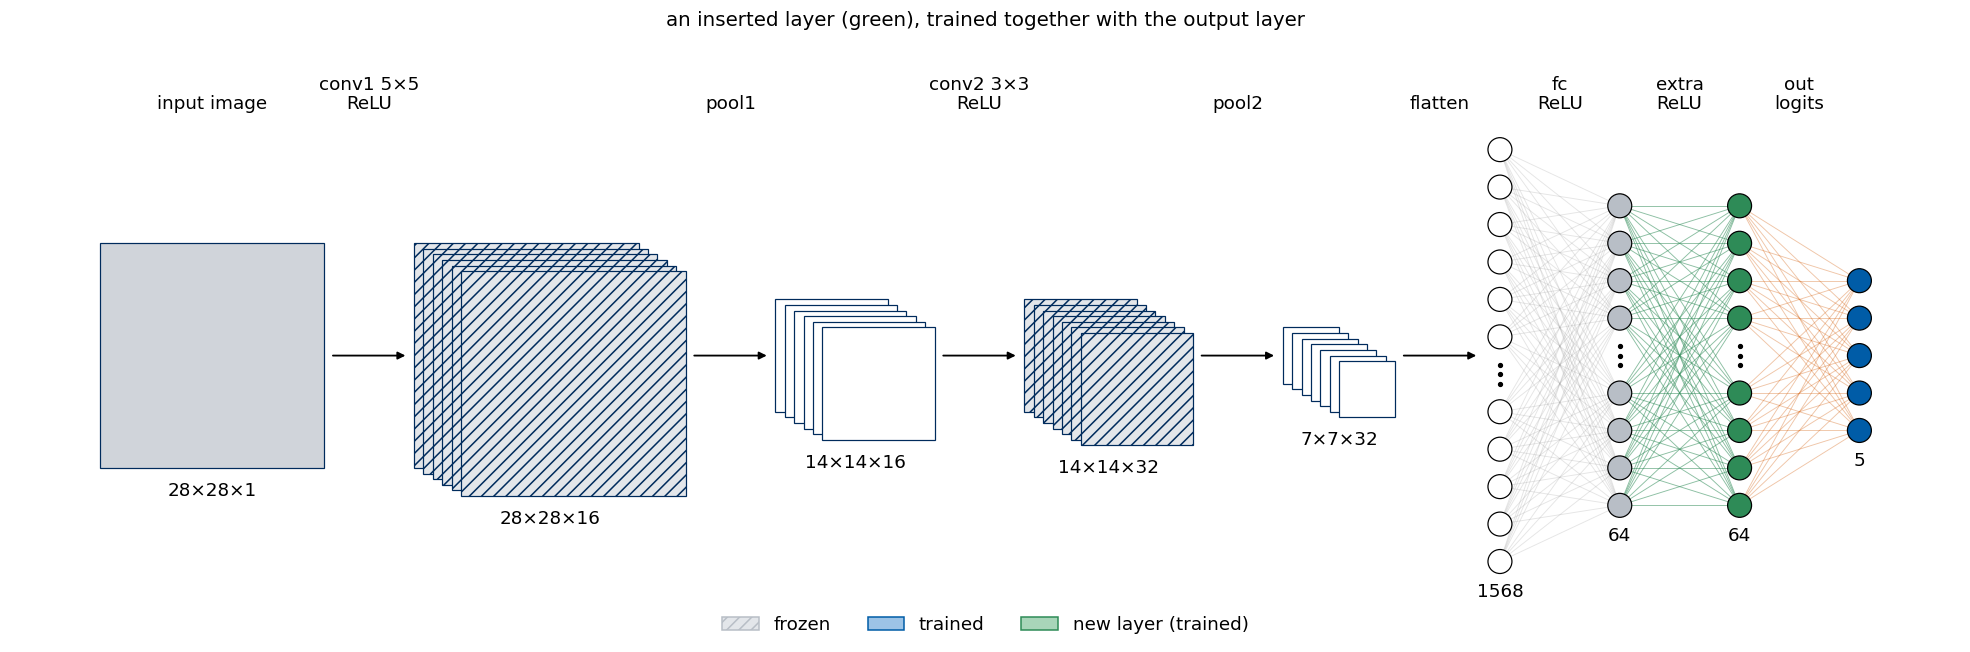

In [31]:
net_d = copy.deepcopy(net_b)                                     # start from (b): body trained on 0-4, head on 5-9
torch.manual_seed(3)
extra = nn.Linear(64, 64)
with torch.no_grad():                                            # the identity: the function is unchanged
    extra.weight.copy_(torch.eye(64))
    extra.bias.zero_()
net_d.head = nn.Sequential(OrderedDict([("fc", net_d.head.fc), ("relu3", nn.ReLU()), ("extra", extra),
                                        ("extra_relu", nn.ReLU()), ("out", net_d.head.out)]))
net_d.eval(); net_b.eval()
with torch.inference_mode():
    assert torch.allclose(net_d(Xt_te), net_b(Xt_te))            # same logits as before the insertion
acc_d0 = accuracy(net_d, Xt_te, yt_te)

for name, p in net_d.named_parameters():                         # train only the new layer and the output layer
    p.requires_grad_(name.startswith(("head.extra", "head.out")))
layer_table(net_d)
before_d = snapshot(net_d)
opt = torch.optim.Adam([p for p in net_d.parameters() if p.requires_grad], lr=1e-3)
train_steps(net_d, opt, X_lab, y_lab, steps=100, seed=2)
max_change(before_d, net_d)
acc_d = accuracy(net_d, Xt_te, yt_te)
print(f"accuracy on digits 5-9: (b) {acc_b:.4f} | identity layer inserted {acc_d0:.4f} | after training it {acc_d:.4f}")
draw_cnn(smallcnn_stages(extra=True), status=[None, "frozen", None, "frozen", None, None, "frozen", "new", "trained"],
         title="an inserted layer (green), trained together with the output layer")
plt.show()

With the identity layer inserted, the accuracy is 0.9461, exactly that of (b), as it must be for an unchanged function. Training the new layer together with the output layer for 100 steps raises it to 0.9482. The table of changes confirms which weights were trained: only `head.extra` and `head.out` moved (by up to 0.05), while the body and `fc` stayed bit for bit unchanged.

### 5.7 A new output layer for a new number of classes

The output layer is the one part of a classifier whose shape is fixed by the task: one output per class. When the number of classes changes, the output layer must be replaced, and the new one starts random. As an example we turn the network of Section 5.6 into a classifier of all ten digits. The new `out` has $64\cdot10+10=650$ parameters; everything else is frozen, so the 64 features computed by the trained layers are reused as they are, and only a linear map from these features to ten logits is learned. The labelled data are 50 training images of each digit, drawn with a NumPy generator, and the accuracy is measured on all 10 000 test images.

layer        parameters   state
body.conv1          416   frozen
body.conv2         4640   frozen
head.fc          100416   frozen
head.extra         4160   frozen
head.out            650   trainable
total            110282   trainable 650, frozen 109632


body.conv1.weight      max|dw| = 0.00e+00
body.conv1.bias        max|dw| = 0.00e+00
body.conv2.weight      max|dw| = 0.00e+00
body.conv2.bias        max|dw| = 0.00e+00
head.fc.weight         max|dw| = 0.00e+00
head.fc.bias           max|dw| = 0.00e+00
head.extra.weight      max|dw| = 0.00e+00
head.extra.bias        max|dw| = 0.00e+00
head.out.weight        max|dw| = 1.98e-01
head.out.bias          max|dw| = 1.58e-01


accuracy on all 10 000 test digits 0-9: 0.7488 (chance level 0.1)


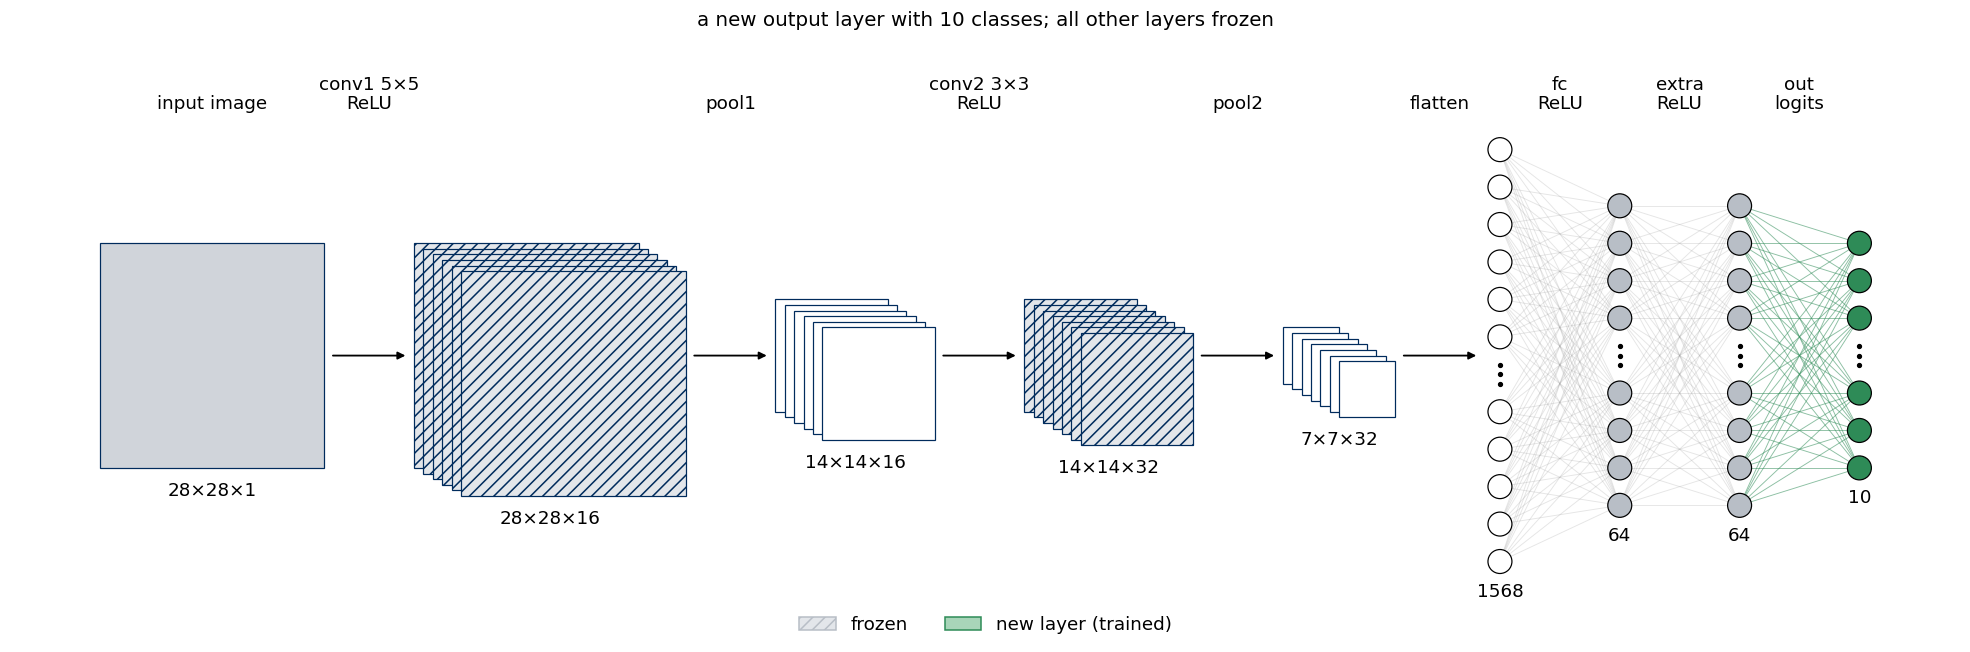

In [32]:
X10_pool, y10_pool = task(Xtr_all, ytr_all, list(range(10)))    # all ten digits, labels 0..9
X10_te, y10_te = task(Xte_all, yte_all, list(range(10)))
rng = np.random.default_rng(0)
idx = np.concatenate([rng.choice(np.flatnonzero(y10_pool.numpy() == c), 50, replace=False) for c in range(10)])
X10, y10 = X10_pool[idx], y10_pool[idx]

net_e = copy.deepcopy(net_d)
torch.manual_seed(4)
net_e.head.out = nn.Linear(64, 10)                               # replaced: 10 outputs instead of 5
for name, p in net_e.named_parameters():
    p.requires_grad_(name.startswith("head.out"))
layer_table(net_e)
before_e = snapshot(net_e)
train_steps(net_e, torch.optim.Adam(net_e.head.out.parameters(), lr=1e-3), X10, y10, steps=300, seed=3)
max_change(before_e, net_e)
acc_e = accuracy(net_e, X10_te, y10_te)
print(f"accuracy on all 10 000 test digits 0-9: {acc_e:.4f} (chance level 0.1)")
draw_cnn(smallcnn_stages(n_out=10, extra=True), status=[None, "frozen", None, "frozen", None, None, "frozen", "frozen", "new"],
         title="a new output layer with 10 classes; all other layers frozen")
plt.show()

Trained on 500 images, the 650 parameters of the new output layer alone classify 0.7488 of all 10 000 test digits correctly, against a chance level of 0.1, and the changes confirm that nothing else moved. The frozen features were learned for the digits 0–4 (the body) and 5–9 (`fc` and `extra`); a linear map on these 64 features separates all ten digits only in part. Unfreezing more layers with a small learning rate, as in the fine-tuning of Section 5.4, is the natural next step.

<hr/>
## 6. Correspondence between PyTorch and JAX/Flax NNX

The table collects every operation of this lab together with its counterpart in Lab 003b, for quick reference when moving between the two frameworks.

| operation | PyTorch | JAX / Flax NNX |
|---|---|---|
| image layout | `(N, C, H, W)` | `(N, H, W, C)` |
| conv kernel shape | `(out, in, kh, kw)` | `(kh, kw, in, out)` |
| dense weight shape | `weight: (out, in)`, $y=xW^T+b$ | `kernel: (in, out)`, $y=xK+b$ |
| save | `torch.save(model.state_dict(), "f.pt")` | `flat = flatten_dict(nnx.to_pure_dict(nnx.state(model, nnx.Param)), sep="/")`; `np.savez("f.npz", **flat)` |
| load into fresh model | `fresh.load_state_dict(torch.load("f.pt", weights_only=True))` | `st = nnx.state(fresh, nnx.Param)`; `nnx.replace_by_pure_dict(st, unflatten_dict(dict(np.load("f.npz")), sep="/"))`; `nnx.update(fresh, st)` |
| list parameters | `for name, p in model.named_parameters()` | `flatten_dict(nnx.to_pure_dict(nnx.state(model, nnx.Param)), sep="/")` |
| one layer's weights | `model.body.conv1.weight.detach().numpy()` | `np.asarray(model.body.conv1.kernel[...])` |
| set weights directly | `with torch.no_grad(): layer.weight.copy_(W)` | `layer.kernel[...] = W` |
| intermediate outputs | `layer.register_forward_hook(fn)`, `handle.remove()` | call submodules step by step, or `nnx.capture(model, nnx.Intermediate, method_outputs=nnx.Intermediate)(x)` |
| feature extractor | `model.body`, or slice `model.body[:6]` | `model.body`; a partial forward pass is implemented as a function |
| new head on trained body | `new.body.load_state_dict(model.body.state_dict())` | `nnx.update(new.body, nnx.state(model.body))` |
| copy a module | `copy.deepcopy(m)` | `nnx.clone(m)` |
| insert a layer | `nn.Sequential(body, extra, nn.ReLU(), head)` | `nnx.Sequential(body, extra, nnx.relu, head)` |
| replace a layer | `net.body.pool1 = nn.AvgPool2d(2)` | `net.body.pool1 = partial(nnx.avg_pool, window_shape=(2, 2), strides=(2, 2))` |
| freeze | `p.requires_grad_(False)`; optimiser gets `net.head.parameters()` | `nnx.Optimizer(net, tx, wrt=head_filter)` and `nnx.grad(..., argnums=nnx.DiffState(0, head_filter))`, or `optax.multi_transform` with `optax.set_to_zero()` for the body |
| where "frozen" lives | in the parameter (`requires_grad`) | in the optimiser and the gradient call (the model has no such flag) |
| per-part learning rates | parameter groups `[{"params": ..., "lr": ...}, ...]` | `optax.multi_transform({"body": optax.adam(1e-4), "head": optax.adam(3e-4)}, labels)` |

The last cell prints the total run time of the notebook.

In [33]:
print(f"total run time of the notebook: {time.time() - t_start:.0f} s")

total run time of the notebook: 147 s
